# Two CMOS inverters (NEAT-RN): finite-capacitance corrections to the chip's noise statistics

Regenerates the NEAT-RN figure of the paper and every number behind it.

Two subthreshold CMOS inverters joined by a capacitance matrix (Freitas et al., arXiv:2605.26267). The exact model is
the Markov jump process of the node charges with EKV subthreshold rates. In units of $V_T$ and $t_u=CV_T/I_0$ the
capacitance enters only through $s=C_T/C$ ($C_T=q_e^2/k_BT\approx6.3$ aF): the tree covariance scales as $s$, the
one-loop correction as $s^2$. So one pipeline run per gate point gives every $C$, and the exact master equation is
solved at each $C$ for comparison. The size of the corrections at a gate point is set by
$\epsilon=\Sigma^{\rm tree}_{ii}/V_T^2$.

**Panels.** The relative variance correction $|\delta\Sigma_{ii}|/\Sigma_{ii}$ of the balanced node (exact, filled) and
the one-loop residual (exact − tree − one loop, open), (a) against the node capacitance and (b) against $\epsilon$.
Diamonds and triangles: the exact error left after pre-compensating the gate voltages with the one-loop map.

**Data.** `data/loop_*.json` (pipeline), `data/me_*.json` (exact master equation) and `data/comp_*.json`
(compensation) were produced by `compute.py` with Daedalus v0.4.0; set the flag below to regenerate them
(about 1.5 h in total).

In [1]:
%matplotlib inline
preparser(False)                     # plain Python literals in this notebook (the Sage kernel preparses by default)
import os, sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
HERE = os.path.abspath('')
sys.path[:0] = [HERE, os.path.dirname(HERE)]
import style
ROOT = style.repo_root(HERE)
import daedalus as dd
import model, compute, analysis
style.apply()
print('Daedalus', dd.__version__)

Daedalus 0.4.0


## 1. The model, typed in the SDE front end

Four state-dependent Poisson sources (node $i$ up or down), each moving both node voltages along $b_i$; no Gaussian
noise and no explicit drift (the drift is the mean of the jumps).

In [2]:
print(open(os.path.join(HERE, 'model.py')).read().split('def build')[1].split('def params_of')[0])
dd.describe_model(model.build().build());

():
    m = SDE('NEAT-RN CMOS inverter pair')
    for p in PARAMS:
        m = m.parameter(p, default=1.0, domain='positive')
    cp1, cn1 = '((ga1+al1-be1)/2)', '((ga1-al1+be1)/2)'
    cp2, cn2 = '((ga2+al2-be2)/2)', '((ga2-al2+be2)/2)'
    return (m.field('u').field('w').drift('u', '0').drift('w', '0')
             .noise('up1', Poisson(rate=f'({cp1} + be1*exp(-u))/s', size='s'), couples={'u': 'b1', 'w': 'b2'})
             .noise('dn1', Poisson(rate=f'(al1*exp(u) + {cn1})/s', size='-s'), couples={'u': 'b1', 'w': 'b2'})
             .noise('up2', Poisson(rate=f'({cp2} + be2*exp(-w))/s', size='s'), couples={'u': 'b2', 'w': 'b1'})
             .noise('dn2', Poisson(rate=f'(al2*exp(w) + {cn2})/s', size='-s'), couples={'u': 'b2', 'w': 'b1'}))



────────────────────────────────────────────────────────────────────────
  NEAT-RN CMOS inverter pair
────────────────────────────────────────────────────────────────────────
Domain         : SDE
Fields         : u; w
Response fields: ut, wt
Mean

## 2. Data

In [3]:
RECOMPUTE = False
if RECOMPUTE:
    for n in compute.NAMES:
        compute.run_loop(n); compute.run_me(n)
    for c in compute.COMP:
        compute.run_comp(*c)
for n in compute.NAMES:
    d = analysis.load(f'loop_{n}.json')
    print(f'{n:6s} gates {np.round(d["gates"][:2], 2)} mV: pipeline {sum(d["wall"].values()):.0f} s '
          f'({len(d["taus"])} lags), v{d["version"]}')

bal1   gates [120.  80.] mV: pipeline 45 s (141 lags), v0.4.0
bal2   gates [ 64. 136.] mV: pipeline 27 s (151 lags), v0.4.0
gen    gates [ 90. 110.] mV: pipeline 43 s (91 lags), v0.4.0
chip1  gates [87.49 54.1 ] mV: pipeline 82 s (121 lags), v0.4.0
chip2  gates [ 31.49 110.1 ] mV: pipeline 113 s (141 lags), v0.4.0


## 3. Tree level, the one-loop law and where the corrections matter

`tree check` is the largest relative difference between the pipeline's tree level and the Lyapunov solution of the
paper's linear model. $c_1$, $c_2$: $\delta\Sigma/\Sigma=c_1\epsilon+c_2\epsilon^2$ at the balanced node.

In [4]:
S = analysis.summary()
fmt = lambda x: '   -' if x is None else f'{x:5.0f}'
print(f'{"point":6s} {"tree check":>10s} {"c1":>7s} {"c2":>7s}   C at 1% / 5% / 10% (aF)   at 1.7 fF: exact / one-loop residual')
for n, o in S.items():
    cr = o['cross']
    print(f'{n:6s} {o["tree_check"]:10.1e} {o["fit"]["c1"]:+7.3f} {o["fit"]["c2"]:+7.2f}   '
          f'{fmt(cr[0.01])} / {fmt(cr[0.05])} / {fmt(cr[0.10])}          {100 * o["chip_exact"]:+.2f}% / {100 * o["chip_resid"]:+.3f}%')
COMP = analysis.compensation()
print('\none-loop pre-compensation at balance (exact error of the balanced variance):')
for r in COMP:
    print(f'  inverter {r["node"]}  C = {r["C"]:6g} aF: naive {100 * r["naive"]:+7.2f}%  ->  compensated {100 * r["comp"]:+7.3f}%'
          f'  (dV_dd = {r["dvdd"]:+.1f} mV{"" if r["converged"] else ", not converged"})')

point  tree check      c1      c2   C at 1% / 5% / 10% (aF)   at 1.7 fF: exact / one-loop residual
bal1      1.2e-15  -0.465   +0.45    2276 /   417 /   187          -1.28% / +0.036%
bal2      6.5e-16  -0.468   +0.46    2511 /   460 /   206          -1.41% / +0.043%
gen       1.1e-15  +0.145   +0.02     138 /    28 /    14          +0.08% / +0.000%
chip1     6.2e-16  -0.438   +0.41    1201 /   220 /    99          -0.68% / +0.010%
chip2     3.6e-16  -0.449   +0.43    1509 /   277 /   124          -0.86% / +0.016%

one-loop pre-compensation at balance (exact error of the balanced variance):
  inverter 1  C =   5000 aF: naive   -0.46%  ->  compensated  +0.005%  (dV_dd = +0.3 mV)
  inverter 1  C =   3000 aF: naive   -0.76%  ->  compensated  +0.013%  (dV_dd = +0.4 mV)
  inverter 1  C =   1770 aF: naive   -1.28%  ->  compensated  +0.037%  (dV_dd = +0.8 mV)
  inverter 1  C =   1000 aF: naive   -2.22%  ->  compensated  +0.117%  (dV_dd = +1.3 mV)
  inverter 1  C =    500 aF: naive   -4.25%  ->

## 4. The figure

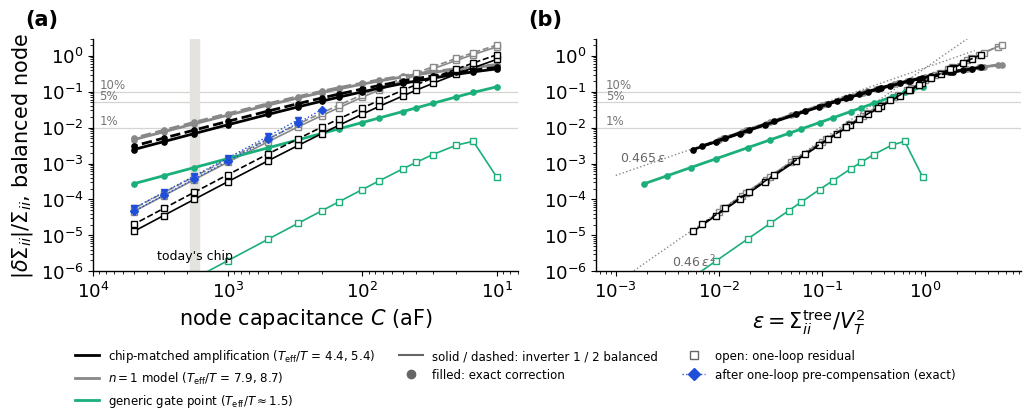

In [5]:
FAM = {'bal1': ('#888888', '-'), 'bal2': ('#888888', '--'), 'chip1': (style.C_TREE, '-'), 'chip2': (style.C_TREE, '--'),
       'gen': ('#1baf7a', '-')}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3))
for n, o in S.items():
    col, ls = FAM[n]
    for ax, x in ((axes[0], o['C']), (axes[1], o['eps'])):
        ax.loglog(x, np.abs(o['exact']), ls, color=col, lw=2.0, marker='o', ms=3.8, zorder=3)
        ax.loglog(x, np.abs(o['resid']), ls, color=col, lw=1.2, marker='s', ms=3.8, mfc='white', zorder=3)
for nd, mk in ((1, 'D'), (2, 'v')):
    pts = sorted((r['C'], abs(r['comp'])) for r in COMP if r['node'] == nd and r['converged'])
    axes[0].loglog([p[0] for p in pts], [p[1] for p in pts], ':', color=style.C_L1, marker=mk, ms=4.5, lw=1.0, zorder=4)
for ax in axes:
    for lv in (0.01, 0.05, 0.10):
        ax.axhline(lv, color='#d6d5d0', lw=0.9, zorder=0)
    ax.set_ylim(1e-6, 3)
for lv in (0.01, 0.05, 0.10):
    axes[0].annotate(f'{int(lv * 100)}%', (9000, lv), color='#777777', fontsize=8.5, va='bottom')
    axes[1].annotate(f'{int(lv * 100)}%', (8e-4, lv), color='#777777', fontsize=8.5, va='bottom')
ax = axes[0]
ax.set_xlim(10000, 7)
ax.axvspan(analysis.C_CHIP / 1.08, analysis.C_CHIP * 1.08, color='#e4e3df', zorder=0)
ax.annotate("today's chip", (analysis.C_CHIP, 2.2e-6), ha='center', fontsize=9)
ax.set_xlabel(r'node capacitance $C$ (aF)'); ax.set_ylabel(r'$|\delta\Sigma_{ii}|/\Sigma_{ii}$, balanced node')
ax = axes[1]
e = np.geomspace(1e-3, 3, 50)
ax.loglog(e, 0.465 * e, ':', color='#888888', lw=1.0); ax.loglog(e, 0.46 * e ** 2, ':', color='#888888', lw=1.0)
ax.annotate(r'$0.465\,\epsilon$', (1.1e-3, 0.465 * 1.1e-3 * 2.2), color='#666666', fontsize=9)
ax.annotate(r'$0.46\,\epsilon^2$', (3.5e-3, 1.3e-6), color='#666666', fontsize=9)
ax.set_xlabel(r'$\epsilon=\Sigma^{\rm tree}_{ii}/V_T^2$')
hs = [Line2D([], [], color=style.C_TREE, lw=2, label=r'chip-matched amplification ($T_{\rm eff}/T$ = 4.4, 5.4)'),
      Line2D([], [], color='#888888', lw=2, label=r'$n=1$ model ($T_{\rm eff}/T$ = 7.9, 8.7)'),
      Line2D([], [], color='#1baf7a', lw=2, label=r'generic gate point ($T_{\rm eff}/T\approx1.5$)'),
      Line2D([], [], color='#666666', lw=1.5, ls='-', label='solid / dashed: inverter 1 / 2 balanced'),
      Line2D([], [], color='#666666', marker='o', ls='', label='filled: exact correction'),
      Line2D([], [], color='#666666', marker='s', mfc='white', ls='', label='open: one-loop residual'),
      Line2D([], [], color=style.C_L1, marker='D', ls=':', lw=1, label='after one-loop pre-compensation (exact)')]
fig.legend(handles=hs, loc='lower center', ncol=3, fontsize=8.5, frameon=False)
style.panel_labels(axes, x=-0.16)
fig.tight_layout(rect=(0, 0.14, 1, 1))
for ext in ('pdf', 'png'):
    fig.savefig(os.path.join(HERE, f'fig_cmos_scaling.{ext}'), dpi=200)
plt.show()